# EDA visual de SPHEREx: cómo se mueve un objeto entre visitas

Notebook para **ver** las imágenes, no para medir. Usa las mismas funciones que el prototipo
(`prototipos/rango_fechas/spherex.py`), así que las imágenes son las mismas que ve la interfaz.

1. **Visitas**: en qué fechas SPHEREx observó la posición.
2. **Secuencia t-1, t, t+1**: tres visitas consecutivas alineadas norte-arriba, con la posición predicha por movimiento propio.
3. **Restas**: qué cambió entre una visita y la siguiente (rojo = aparece, azul = desaparece).
4. **Parpadeo animado** de todas las visitas.
5. **Otra banda**: la misma secuencia en una segunda banda (otra longitud de onda).
6. **Manchas moradas**: de dónde salen los píxeles sin dato.
7. **EDA de las bandas**: el filtro lineal variable, cuándo se observa cada banda, el campo en las 6 bandas y un espectro.
8. **Cómo armar el parpadeo del visor**: frames de visitas distintas, λ igualada, zoom con marca fija y selector de banda.

Cambia la celda de configuración y vuelve a correr todo (*Run All*). Los recortes se guardan en
`data/cache/prototipo/` y la segunda vez no se descargan.

In [1]:
import sys, math, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import animation
from IPython.display import HTML, display
import yaml
from astropy.time import Time
from astropy.io import fits
from astropy.wcs import WCS

RAIZ = Path.cwd()
while not (RAIZ / "prototipos").exists() and RAIZ != RAIZ.parent:   # funciona desde data/ o desde la raíz
    RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ / "prototipos" / "rango_fechas"))
import spherex

warnings.filterwarnings("ignore")
plt.rcParams["animation.embed_limit"] = 50  # MB, para que la animación quepa en el notebook
# Píxeles sin dato (núcleo saturado, rayos cósmicos, fuera del detector) en morado, para no confundirlos con brillo.
GRIS = plt.get_cmap("gray").copy(); GRIS.set_bad("#6a2c8a")
DIF = plt.get_cmap("RdBu_r").copy(); DIF.set_bad("#6a2c8a")

## 0. Configuración

| id | qué se espera |
|---|---|
| `barnard` | movimiento grande y brillante: el caso más claro (banda 2) |
| `wise_0855` | movimiento grande pero débil: subir `POR_VISITA` a 4–6 (banda 5) |
| `eps_ind_b` | enana marrón, roja (bandas 5–6) |
| `rw_aur`, `r_dra` | control: varían de brillo pero **no** se mueven |

`T` es el índice de la visita central (`None` = la del medio). `DESPLAZAMIENTOS` define qué visitas se muestran
alrededor de `T`: `(-1, 0, 1)` es t-1, t, t+1; `(-1, 0, 2)` es t-1, t, t+2.

In [2]:
CAMPO = "barnard"
BANDA = None              # None = la recomendada en data/campos_de_prueba.yml
BANDA_EXTRA = 5           # segunda banda (1-6); 5 se observa a la vez que la 2 (ver 7.2). None = saltar sección 5
INICIO, FIN = "2025-04-01", Time.now().isot[:10]
SIZE = 0.1                # grados de lado del recorte (0.1° ≈ 59 px de 6.15")
POR_VISITA = 3            # exposiciones sumadas (mediana) por visita: más = menos ruido, más descarga
T = None                  # visita central; None = la del medio
DESPLAZAMIENTOS = (-1, 0, 1)
ZOOM_PX = None            # p. ej. 25 para recortar al centro; None = recorte entero

campos = {c["id"]: c for c in yaml.safe_load((RAIZ / "data" / "campos_de_prueba.yml").read_text())["campos"]}
c = campos[CAMPO]
BANDA = BANDA or c["banda_recomendada"]

def posicion(anio):
    """Posición J2000 del catálogo propagada con el movimiento propio (lineal, sin paralaje)."""
    dt = anio - 2000.0
    dec = c["dec_deg"] + c["pmdec"] * dt / 3.6e6
    ra = c["ra_deg"] + c["pmra"] * dt / 3.6e6 / math.cos(math.radians(c["dec_deg"]))
    return ra % 360, dec

anio_medio = (Time(INICIO).decimalyear + Time(FIN).decimalyear) / 2
RA, DEC = posicion(anio_medio)
N_PX = int(math.ceil(SIZE * 3600 / spherex.ESCALA_ARCSEC))
W = spherex.wcs_destino(RA, DEC, N_PX)       # rejilla común norte-arriba, este a la izquierda
pm = math.hypot(c["pmra"], c["pmdec"]) / 1000
print(f"{c['nombre']} | banda {BANDA} {spherex.BANDAS_UM[BANDA]} µm | centro RA {RA:.5f} Dec {DEC:.5f} (época {anio_medio:.2f})")
print(f"Movimiento propio: {pm:.2f}\"/año = {pm/spherex.ESCALA_ARCSEC:.2f} px/año | recorte {N_PX}x{N_PX} px")

Estrella de Barnard | banda 2 (1.1, 1.62) µm | centro RA 269.44626 Dec 4.76837 (época 2026.06)
Movimiento propio: 10.39"/año = 1.69 px/año | recorte 59x59 px


## 1. Visitas disponibles

Una consulta SIA2 (barata: no baja imágenes). Las exposiciones a menos de 5 días se agrupan en una *visita*.

In [3]:
def visitas_de(banda):
    obs, avisos = spherex.buscar(RA, DEC, banda, INICIO, FIN)
    for a in avisos: print("AVISO:", a)
    return spherex.agrupar_visitas(obs)

visitas = visitas_de(BANDA)
pd.DataFrame([dict(visita=i, inicio=v[0].iso[:10], fin=v[-1].iso[:10], exposiciones=len(v),
                   dias_desde_la_primera=round(v[0].mjd - visitas[0][0].mjd, 1))
              for i, v in enumerate(visitas)])

,visita,inicio,fin,exposiciones,dias_desde_la_primera
0,0,2025-08-21,2025-08-30,18,0.0
1,1,2026-03-15,2026-03-22,19,205.1
2,2,2026-08-18,2026-08-28,24,361.9
3,3,2026-09-22,2026-09-22,1,396.6


## 2. Cargar y alinear las visitas

Por cada visita se bajan `POR_VISITA` recortes, se les resta la luz zodiacal, se enmascaran píxeles malos,
se **reproyectan** a la rejilla común (cada apuntado viene girado distinto) y se combinan con la mediana.

In [4]:
def cargar(banda, visitas):
    grupos = spherex.elegir_fotogramas(visitas, max_visitas=len(visitas), por_visita=POR_VISITA)
    fot = []
    for i, g in enumerate(grupos):
        print(f"\rbanda {banda}: visita {i+1}/{len(grupos)}", end="")
        f = spherex.apilar([spherex.procesar(spherex.bajar_recorte(o, RA, DEC, SIZE), o, RA, DEC, N_PX) for o in g])
        f.datos = f.datos - np.nanmedian(f.datos)          # fondo a 0 para comparar entre visitas
        fot.append(f)
    print()
    return fot

fot = cargar(BANDA, visitas)

def etiqueta(f):
    lam = f"{f.lambda_um:.3f} µm" if f.lambda_um else "λ ?"
    return f"{f.obs.iso[:10]} · {lam} · {f.n_apiladas} exp."

def norma(fs):
    """Una misma escala para todas las imágenes: si no, los cambios de brillo se inventan."""
    todo = np.concatenate([f.datos[np.isfinite(f.datos)] for f in fs])
    lo, hi = np.percentile(todo, [1, 99.7])
    a = 0.1
    def estirar(d):                       # asinh entre lo y hi; los NaN siguen siendo NaN (morado)
        x = np.clip((d - lo) / (hi - lo), 0, 1)
        return np.ma.masked_invalid(np.arcsinh(x / a) / np.arcsinh(1 / a))
    return estirar

def anio(f):
    return Time(f.obs.mjd, format="mjd").decimalyear

def marcar(ax, f, color="lime"):
    """Círculo en la posición predicha por movimiento propio en la fecha de la imagen."""
    x, y = W.world_to_pixel_values(*posicion(anio(f)))
    ax.add_patch(plt.Circle((x, y), 3, fill=False, color=color, lw=1.2))

def encuadrar(ax):
    ax.set_xticks([]); ax.set_yticks([])
    if ZOOM_PX:
        m = N_PX / 2
        ax.set_xlim(m - ZOOM_PX / 2, m + ZOOM_PX / 2); ax.set_ylim(m - ZOOM_PX / 2, m + ZOOM_PX / 2)

print(f"{len(fot)} visitas cargadas")

banda 2: visita 3/4

banda 2: visita 4/4
4 visitas cargadas


## 3. Secuencia t-1, t, t+1

Arriba, las tres visitas con **la misma escala de grises**. El círculo verde es donde el movimiento propio dice
que debería estar el objeto en esa fecha: si el objeto se mueve, la mancha sigue al círculo.
Abajo, la resta entre visitas consecutivas: un par **azul → rojo** es un objeto que se desplazó.
Norte arriba, este a la izquierda. **Morado = sin dato** (núcleo saturado o píxel enmascarado).
Los dipolos pequeños en estrellas quietas vecinas son restos de alineación y de PSF, no movimiento.
De dónde sale cada mancha morada: sección 6.

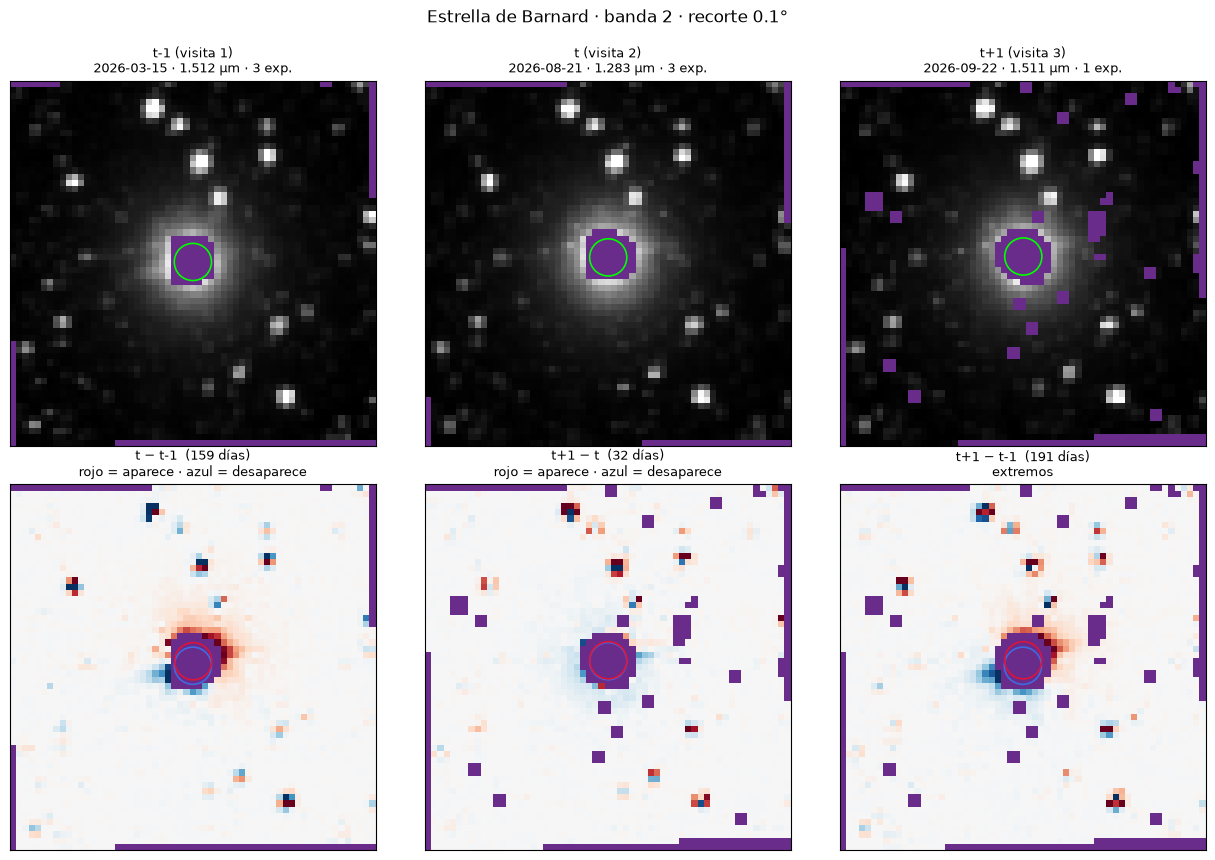

Ojo: las visitas están a λ distintas (1.283–1.512 µm): parte del cambio de brillo es el filtro lineal variable, no el objeto.


In [5]:
def secuencia(fot, banda, T=T, despl=DESPLAZAMIENTOS):
    t = len(fot) // 2 if T is None else T
    idx = [t + d for d in despl if 0 <= t + d < len(fot)]
    nombres = {i: ("t" if i == t else f"t{i - t:+d}") for i in idx}
    if len(idx) < len(despl):
        print(f"Aviso: con T={t} y {len(fot)} visitas solo existen {[nombres[i] for i in idx]}")
    sel = [fot[i] for i in idx]
    n = norma(sel)
    fig, axs = plt.subplots(2, len(sel), figsize=(4.2 * len(sel), 8.6), squeeze=False)
    for k, (i, f) in enumerate(zip(idx, sel)):
        ax = axs[0, k]
        ax.imshow(n(f.datos), origin="lower", cmap=GRIS, vmin=0, vmax=1)
        marcar(ax, f); encuadrar(ax)
        ax.set_title(f"{nombres[i]} (visita {i})\n{etiqueta(f)}", fontsize=9)
    # restas consecutivas, con escala simétrica común
    restas = [(sel[k + 1].datos - sel[k].datos, f"{nombres[idx[k+1]]} − {nombres[idx[k]]}") for k in range(len(sel) - 1)]
    lim = np.nanpercentile(np.abs(np.concatenate([r[np.isfinite(r)] for r, _ in restas])), 99.5) if restas else 1
    for k, (r, titulo) in enumerate(restas):
        ax = axs[1, k]
        ax.imshow(r, origin="lower", cmap=DIF, vmin=-lim, vmax=lim)
        marcar(ax, sel[k], "royalblue"); marcar(ax, sel[k + 1], "crimson"); encuadrar(ax)
        dias = sel[k + 1].obs.mjd - sel[k].obs.mjd
        ax.set_title(f"{titulo}  ({dias:.0f} días)\nrojo = aparece · azul = desaparece", fontsize=9)
    # última casilla: resta entre los extremos (la base temporal más larga)
    ax = axs[1, -1]
    r = sel[-1].datos - sel[0].datos
    ax.imshow(r, origin="lower", cmap=DIF, vmin=-lim, vmax=lim)
    marcar(ax, sel[0], "royalblue"); marcar(ax, sel[-1], "crimson"); encuadrar(ax)
    ax.set_title(f"{nombres[idx[-1]]} − {nombres[idx[0]]}  ({sel[-1].obs.mjd - sel[0].obs.mjd:.0f} días)\nextremos", fontsize=9)
    fig.suptitle(f"{c['nombre']} · banda {banda} · recorte {SIZE}°", y=0.995)
    fig.tight_layout(); plt.show()
    lams = [f.lambda_um for f in sel if f.lambda_um]
    if lams and max(lams) - min(lams) > 0.02:
        print(f"Ojo: las visitas están a λ distintas ({min(lams):.3f}–{max(lams):.3f} µm): parte del cambio de brillo "
              "es el filtro lineal variable, no el objeto.")

secuencia(fot, BANDA)

## 4. Parpadeo de todas las visitas

La animación recorre todas las visitas en orden de fecha con la misma escala. Usa los controles para pausar,
ir cuadro a cuadro o cambiar la velocidad.

In [6]:
def parpadeo(fot, banda, ms=700):
    n = norma(fot)
    fig, ax = plt.subplots(figsize=(5.5, 5.8))
    im = ax.imshow(n(fot[0].datos), origin="lower", cmap=GRIS, vmin=0, vmax=1)
    circ = plt.Circle((0, 0), 3, fill=False, color="lime", lw=1.2); ax.add_patch(circ)
    encuadrar(ax)
    tit = ax.set_title("")
    def paso(i):
        f = fot[i]
        im.set_data(n(f.datos))
        circ.center = W.world_to_pixel_values(*posicion(anio(f)))
        tit.set_text(f"{c['nombre']} · banda {banda}\nvisita {i}: {etiqueta(f)}")
        return im, circ, tit
    an = animation.FuncAnimation(fig, paso, frames=len(fot), interval=ms)
    plt.close(fig)
    return HTML(an.to_jshtml(default_mode="loop"))

parpadeo(fot, BANDA)

### Todas las visitas en una rejilla

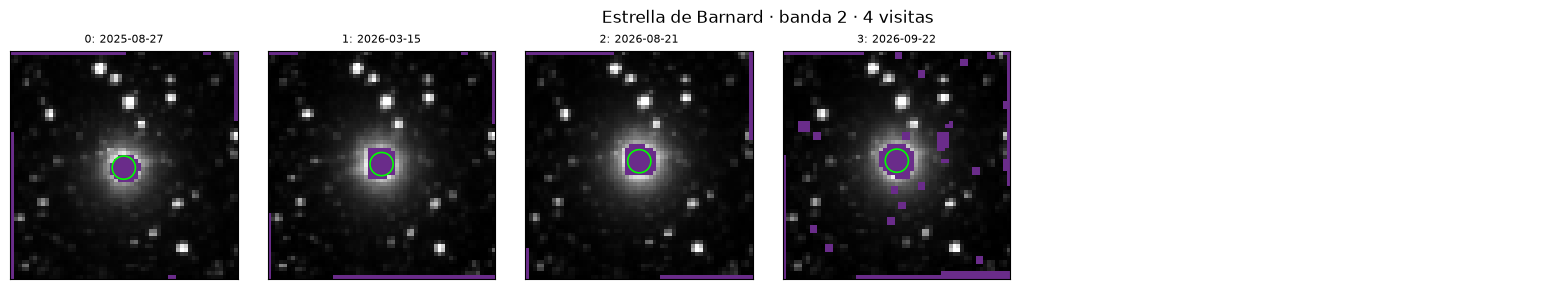

In [7]:
def rejilla(fot, banda, cols=6):
    n = norma(fot)
    filas = math.ceil(len(fot) / cols)
    fig, axs = plt.subplots(filas, cols, figsize=(2.6 * cols, 2.9 * filas), squeeze=False)
    for ax in axs.flat: ax.axis("off")
    for i, f in enumerate(fot):
        ax = axs.flat[i]; ax.axis("on")
        ax.imshow(n(f.datos), origin="lower", cmap=GRIS, vmin=0, vmax=1); marcar(ax, f); encuadrar(ax)
        ax.set_title(f"{i}: {f.obs.iso[:10]}", fontsize=8)
    fig.suptitle(f"{c['nombre']} · banda {banda} · {len(fot)} visitas"); fig.tight_layout(); plt.show()

rejilla(fot, BANDA)

## 5. Otra banda

La misma secuencia en `BANDA_EXTRA`. Es otra longitud de onda (otro detector), así que las estrellas cambian de brillo
relativo: los objetos fríos, como las enanas marrones, son más brillantes en las bandas 5–6. Las bandas se observan
en parejas simultáneas (1–4, 2–5, 3–6; ver sección 7.2): con la banda 5 junto a la 2, las fechas coinciden.

Banda 5: (3.83, 4.41) µm


banda 5: visita 3/4

banda 5: visita 4/4


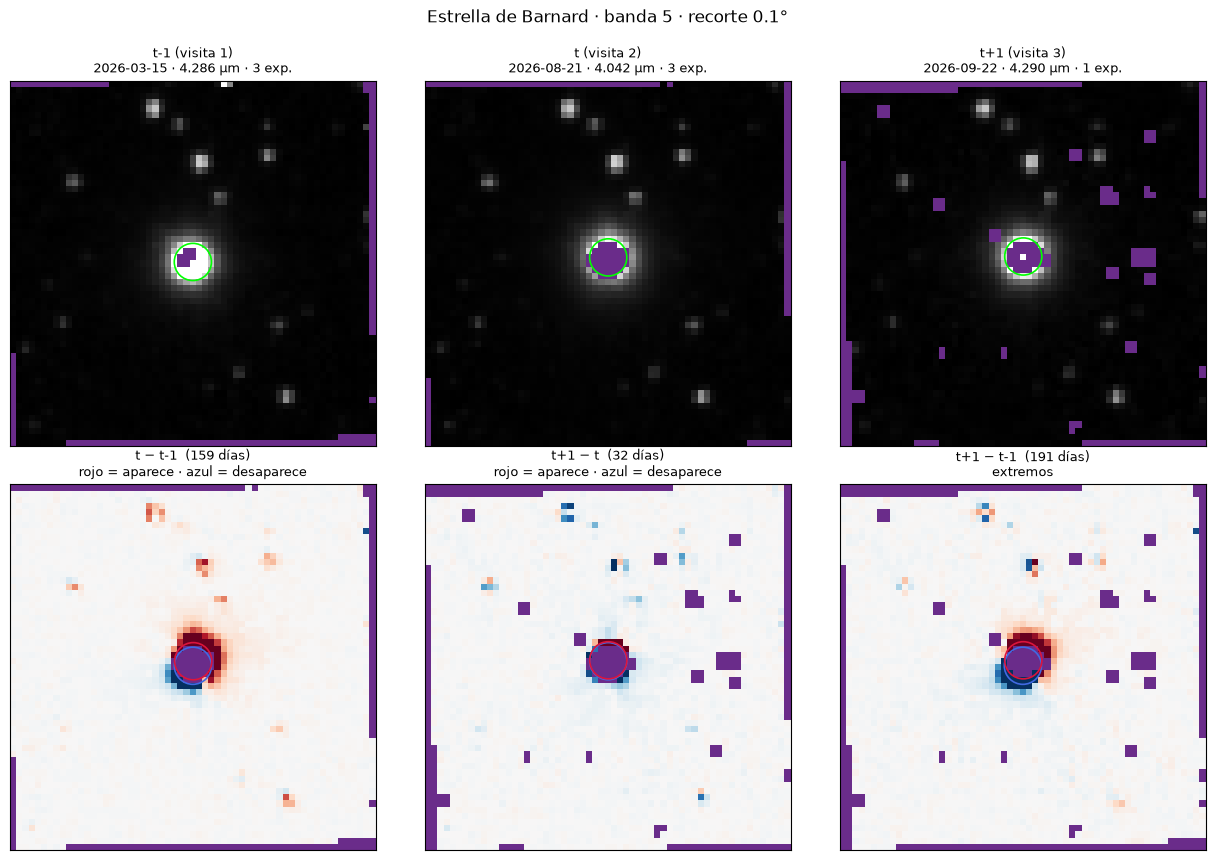

Ojo: las visitas están a λ distintas (4.042–4.290 µm): parte del cambio de brillo es el filtro lineal variable, no el objeto.


In [8]:
if BANDA_EXTRA:
    print(f"Banda {BANDA_EXTRA}: {spherex.BANDAS_UM[BANDA_EXTRA]} µm")
    visitas_extra = visitas_de(BANDA_EXTRA)
    fot_extra = cargar(BANDA_EXTRA, visitas_extra)
    secuencia(fot_extra, BANDA_EXTRA)

In [9]:
if BANDA_EXTRA:
    display(parpadeo(fot_extra, BANDA_EXTRA))

### Las dos bandas lado a lado en la misma visita

Para cada visita de la banda principal se busca la visita más cercana en fecha de la otra banda.

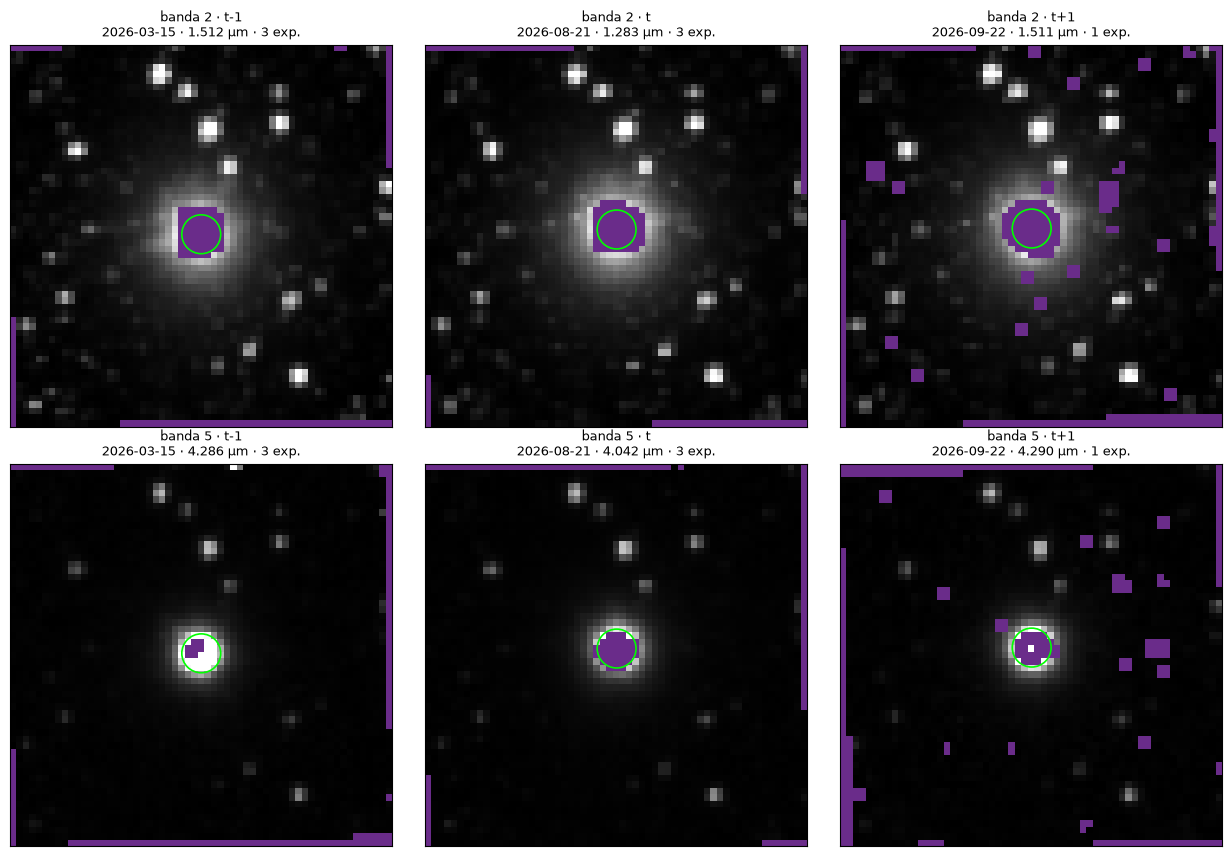

In [10]:
if BANDA_EXTRA:
    t = len(fot) // 2 if T is None else T
    idx = [t + d for d in DESPLAZAMIENTOS if 0 <= t + d < len(fot)]
    fig, axs = plt.subplots(2, len(idx), figsize=(4.2 * len(idx), 8.6), squeeze=False)
    for fila, (fs, b) in enumerate([(fot, BANDA), (fot_extra, BANDA_EXTRA)]):
        n = norma(fs); usado = []
        for k, i in enumerate(idx):
            ref = fot[i].obs.mjd
            f = min(fs, key=lambda x: abs(x.obs.mjd - ref))
            ax = axs[fila, k]
            ax.imshow(n(f.datos), origin="lower", cmap=GRIS, vmin=0, vmax=1); marcar(ax, f); encuadrar(ax)
            rep = " (repetida: no hay otra más cercana)" if fila and k and f is usado[-1] else ""
            usado.append(f)
            ax.set_title(f"banda {b} · t{i - t:+d}{rep}\n{etiqueta(f)}".replace("t+0", "t"), fontsize=9)
    fig.tight_layout(); plt.show()

## 6. ¿De dónde salen las manchas moradas?

Morado = **píxel sin dato**. Hay tres causas, y ninguna es que el objeto cambie:

1. **Borde**: cada visita apunta con el detector girado distinto; al alinear todo norte-arriba, las esquinas de la
   rejilla común quedan fuera del recorte original. Por eso los bordes morados cambian de una visita a otra.
2. **Píxeles marcados en `FLAGS`**: rayos cósmicos (`TRANSIENT`), píxeles calientes, etc. Caen al azar en cada
   exposición. Al hacer la **mediana de varias exposiciones** se rellenan con las otras; si la visita tiene una sola
   exposición (como t+1 de Barnard en banda 2), quedan todos a la vista.
3. **El núcleo de una estrella muy brillante**: el detector se satura y el procesado a bordo marca esos píxeles
   (`SUR_ERROR`, `TRANSIENT`). Su tamaño depende de cuánto brille la estrella **a esa λ**, así que cambia con la banda
   y con la exposición.

Abajo, las exposiciones de la visita t una por una, con el borde en gris y los píxeles marcados en morado.

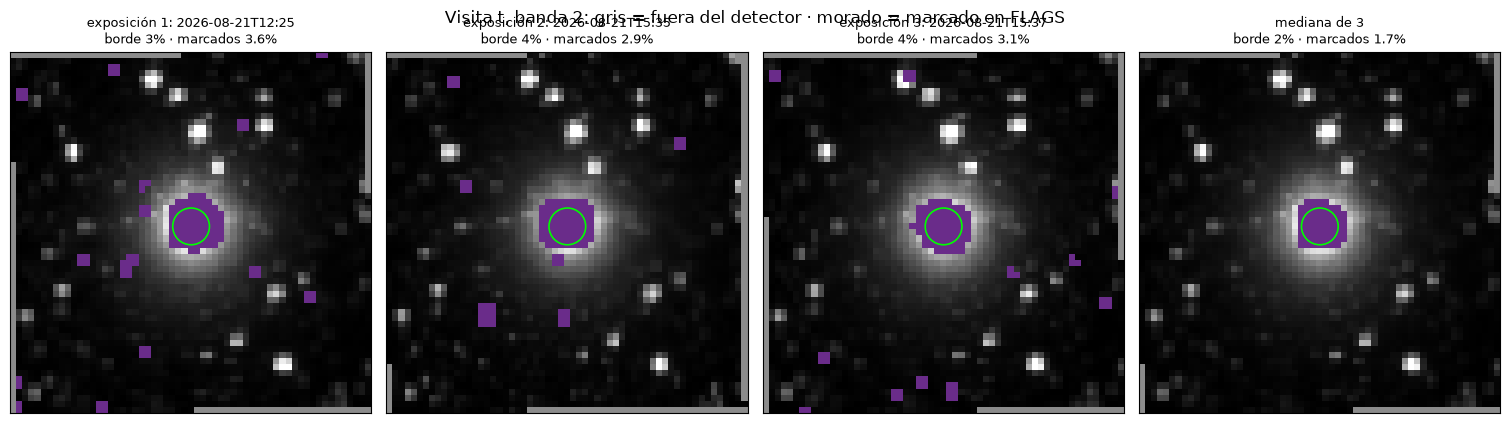

In [11]:
t = len(fot) // 2 if T is None else T
g = spherex.elegir_fotogramas([visitas[t]], 1, POR_VISITA)[0]
exps = [spherex.procesar(spherex.bajar_recorte(o, RA, DEC, SIZE), o, RA, DEC, N_PX) for o in g]
med = spherex.apilar(exps)
paneles = [(f, f"exposición {k+1}: {f.obs.iso[:16]}") for k, f in enumerate(exps)] + [(med, f"mediana de {len(exps)}")]
n = norma([type(f)(**{**f.__dict__, "datos": f.datos - np.nanmedian(f.datos)}) for f in exps])
fig, axs = plt.subplots(1, len(paneles), figsize=(3.8 * len(paneles), 4.3), squeeze=False)
for ax, (f, titulo) in zip(axs[0], paneles):
    sin = ~np.isfinite(f.datos)
    borde, marcado = sin & ~f.cobertura, sin & f.cobertura
    ax.imshow(n(f.datos - np.nanmedian(f.datos)), origin="lower", cmap=GRIS, vmin=0, vmax=1)
    capa = np.zeros((N_PX, N_PX, 4)); capa[borde] = (0.55, 0.55, 0.55, 1)
    ax.imshow(capa, origin="lower"); marcar(ax, f); encuadrar(ax)
    ax.set_title(f"{titulo}\nborde {100*borde.mean():.0f}% · marcados {100*marcado.mean():.1f}%", fontsize=9)
fig.suptitle(f"Visita t, banda {BANDA}: gris = fuera del detector · morado = marcado en FLAGS"); fig.tight_layout(); plt.show()

Qué bits de `FLAGS` aparecen en esas exposiciones. La descripción viene de la propia cabecera (`MSKDnnnn`); `% núcleo` es la fracción dentro de 3 px de la posición predicha del objeto.

In [12]:
filas = {}
for o in g:
    with fits.open(spherex.bajar_recorte(o, RA, DEC, SIZE)) as h:
        fl, cab = h["FLAGS"].data.astype(np.int64), h["FLAGS"].header
        x, y = WCS(h["IMAGE"].header).world_to_pixel_values(*posicion(Time(o.mjd, format="mjd").decimalyear))
    yy, xx = np.mgrid[:fl.shape[0], :fl.shape[1]]
    nucleo = (xx - x)**2 + (yy - y)**2 <= 9
    for b, nom in spherex.definiciones_flags(cab).items():
        m = (fl >> b) & 1 == 1
        r = filas.setdefault(nom, dict(bit=b, nombre=nom, descripcion=str(cab.get(f"MSKD{b:04d}", "")), pct=[], nuc=[]))
        r["pct"].append(100 * m.mean()); r["nuc"].append(100 * m[nucleo].mean() if nucleo.any() else np.nan)
tabla = pd.DataFrame([dict(bit=r["bit"], nombre=r["nombre"], descripcion=r["descripcion"],
                           **{"% píxeles": round(np.mean(r["pct"]), 2), "% núcleo": round(np.nanmean(r["nuc"]), 1)},
                           en_el_notebook="se enmascara (morado)" if r["nombre"] in spherex.BITS_ENMASCARAR else
                                          ("informativo, se ignora" if r["nombre"] in spherex.BITS_INFORMATIVOS else "se deja"))
                      for r in filas.values() if np.mean(r["pct"]) > 0]).sort_values("bit")
tabla

,bit,nombre,descripcion,% píxeles,% núcleo,en_el_notebook
0,0,TRANSIENT,Transient detected during SUR,1.75,80.5,se enmascara (morado)
1,1,OVERFLOW,Overflow detected during SUR,0.19,22.0,se deja
2,2,SUR_ERROR,Error in onboard processing,1.45,95.2,se enmascara (morado)
3,6,NONFUNC,Permanently unusable,0.15,0.0,se enmascara (morado)
4,11,COLD,Anomalously low signal,0.03,0.0,se enmascara (morado)
5,17,PERSIST,Persistent charge above threshold,0.13,0.0,se deja
6,19,OUTLIER,Pixel flagged by Detect Outliers,0.01,0.0,se enmascara (morado)
7,21,SOURCE,Pixel mapped to a known source,99.99,100.0,"informativo, se ignora"
8,26,BLOOM,Pixel part of a bloom artifact,1.57,100.0,se deja
9,28,HALO,Pixel part of a transient halo,0.90,0.0,se deja


---
# 7. EDA de las bandas

## 7.1 Las seis bandas y el filtro lineal variable

SPHEREx tiene **seis detectores**, y cada uno es una **banda**. Pero no tiene un filtro fijo por banda como una
cámara normal: delante de cada detector hay un **filtro lineal variable (LVF)**, un filtro cuya longitud de onda
cambia de forma continua de un extremo del detector al otro. Una fila del detector ve, por ejemplo, 1,20 µm y otra
fila más allá ve 1,50 µm.

La consecuencia:

- **La longitud de onda depende de dónde cae la estrella en el detector.** Cada vez que el telescopio apunta, la
  estrella cae en otra fila, así que se mide a otra λ. Por eso cada imagen trae su λ (`1.512 µm`, `1.283 µm`...).
- **Así se arma un espectro**: observando la misma estrella muchas veces, en filas distintas, se cubre toda la
  banda. Con 6 bandas, de 0,75 a 5 µm, salen 102 "colores".
- **Para ver movimiento es un problema**: entre dos visitas la estrella brilla distinto solo porque se midió a otra
  λ. Un cambio de brillo en el parpadeo no significa que el objeto cambió.

`R` es el poder de resolución, λ/Δλ: cuánto de fino corta el espectro cada banda. Las bandas 5 y 6 cortan unas 3
veces más fino. La columna de la derecha son rasgos conocidos que caen en cada rango (orientativo).

In [13]:
R = {1: 39, 2: 41, 3: 41, 4: 35, 5: 112, 6: 128}      # skill spherex-datos / docs/02_DATOS_SPHEREX.md
QUE = {1: "luz de estrellas, casi visible",
       2: "luz de estrellas (infrarrojo cercano)",
       3: "luz de estrellas; menos polvo interpuesto",
       4: "hielo de agua (~3,0 µm), PAH (3,3 µm), metano de enanas marrones (~3,3 µm, absorbe)",
       5: "hielo de CO₂ (4,27 µm); las enanas marrones frías brillan aquí",
       6: "hielo de CO (4,67 µm)"}
pd.DataFrame([dict(banda=b, lambda_min_um=lo, lambda_max_um=hi, R=R[b],
                   ancho_de_un_canal_um=round((lo + hi) / 2 / R[b], 3),
                   canales_aprox=round(np.log(hi / lo) * R[b]), que_destaca=QUE[b])
              for b, (lo, hi) in spherex.BANDAS_UM.items()]).set_index("banda")

,lambda_min_um,lambda_max_um,R,ancho_de_un_canal_um,canales_aprox,que_destaca
banda,,,,,,
1,0.75,1.09,39,0.024,15,"luz de estrellas, casi visible"
2,1.10,1.62,41,0.033,16,luz de estrellas (infrarrojo cercano)
3,1.63,2.41,41,0.049,16,luz de estrellas; menos polvo interpuesto
4,2.42,3.82,35,0.089,16,"hielo de agua (~3,0 µm), PAH (3,3 µm), metano ..."
5,3.83,4.41,112,0.037,16,"hielo de CO₂ (4,27 µm); las enanas marrones fr..."
6,4.42,5.00,128,0.037,16,"hielo de CO (4,67 µm)"


## 7.2 ¿Cuándo se observa cada banda?

Una consulta por banda (barata). Cada punto es una exposición.

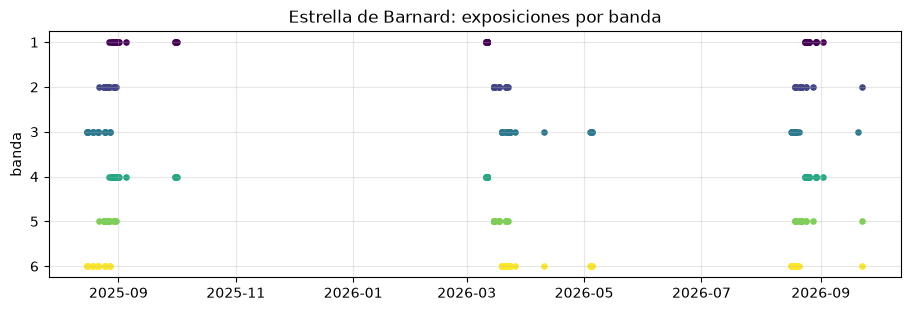

Fracción de exposiciones simultáneas (fila con columna):


,1,2,3,4,5,6
1,1.0,0.0,0.00,0.98,0.0,0.00
2,0.0,1.0,0.00,0.00,1.0,0.00
3,0.0,0.0,1.00,0.00,0.0,0.95
4,1.0,0.0,0.00,1.00,0.0,0.00
5,0.0,1.0,0.00,0.00,1.0,0.00
6,0.0,0.0,0.97,0.00,0.0,1.00


In [14]:
obs_banda = {b: spherex.buscar(RA, DEC, b, INICIO, FIN)[0] for b in range(1, 7)}
COLOR = {b: plt.get_cmap("viridis")(i / 5) for i, b in enumerate(range(1, 7))}
fig, ax = plt.subplots(figsize=(11, 3.2))
for b, obs in obs_banda.items():
    ax.scatter([pd.Timestamp(Time(o.mjd, format="mjd").datetime) for o in obs], np.full(len(obs), b), s=14, color=COLOR[b])
ax.set_yticks(range(1, 7)); ax.set_ylabel("banda"); ax.invert_yaxis(); ax.grid(alpha=.3)
ax.set_title(f"{c['nombre']}: exposiciones por banda"); plt.show()

# ¿Qué bandas se observan en el mismo instante? Fracción de exposiciones de la fila con una de la columna a < 1 min.
mat = pd.DataFrame(index=range(1, 7), columns=range(1, 7), dtype=float)
for a in range(1, 7):
    ta = np.array([o.mjd for o in obs_banda[a]])
    for b in range(1, 7):
        tb = np.array([o.mjd for o in obs_banda[b]])
        mat.loc[a, b] = np.mean([np.min(np.abs(tb - x)) < 1 / 1440 for x in ta]) if len(ta) and len(tb) else np.nan
print("Fracción de exposiciones simultáneas (fila con columna):")
mat.round(2)

**Qué mirar:** las bandas van **en parejas que se observan a la vez**: 1 con 4, 2 con 5 y 3 con 6. SPHEREx separa la luz
con un espejo dicroico en dos planos focales (bandas cortas 1–3 y largas 4–6), así que cada par de detectores mira
el mismo trozo de cielo en el mismo instante. Las tres parejas miran trozos distintos, por eso pasan sobre el objeto
en fechas distintas.

Por eso `BANDA_EXTRA = 5` sirve para comparar con la banda 2: mismas fechas, otra longitud de onda.

## 7.3 Una muestra de exposiciones de cada banda

Bajamos `N_POR_BANDA` exposiciones de cada banda repartidas en todo el rango de fechas. Con esto se ve el filtro
en acción y se arma un espectro. La primera vez son ~6×`N_POR_BANDA` recortes de ~4 MB.

In [15]:
N_POR_BANDA = 8
from concurrent.futures import ThreadPoolExecutor

def una_exposicion(par):
    b, o = par
    try:
        f = spherex.procesar(spherex.bajar_recorte(o, RA, DEC, SIZE), o, RA, DEC, N_PX)
    except Exception as e:               # IRSA a veces responde 503 aunque se reintente
        return b, e
    f.datos = f.datos - np.nanmedian(f.datos)
    return b, f

pedidos = []
for b, obs in obs_banda.items():
    if obs:
        idx = np.unique(np.linspace(0, len(obs) - 1, N_POR_BANDA).astype(int))
        pedidos += [(b, obs[i]) for i in idx]
with ThreadPoolExecutor(spherex.PARALELO) as ex:
    resultado = list(ex.map(una_exposicion, pedidos))
fallidos = [par for par, (_, f) in zip(pedidos, resultado) if isinstance(f, Exception)]
if fallidos:                             # segunda pasada, de a uno y sin prisa
    import time; time.sleep(10)
    resultado = [r for r in resultado if not isinstance(r[1], Exception)] + [una_exposicion(par) for par in fallidos]
muestra = sorted([(b, f) for b, f in resultado if not isinstance(f, Exception)], key=lambda x: (x[0], x[1].obs.mjd))
for b, f in resultado:
    if isinstance(f, Exception): print(f"AVISO: banda {b}: se salta una exposición ({type(f).__name__}: {str(f)[:80]})")
print(f"{len(muestra)} de {len(pedidos)} exposiciones procesadas")

48 de 48 exposiciones procesadas


### La λ de cada exposición

Cada punto es una exposición; la franja es el rango completo de la banda. Dentro de una misma banda, la λ salta
según dónde cayó el objeto en el detector, sin ningún orden por fecha.

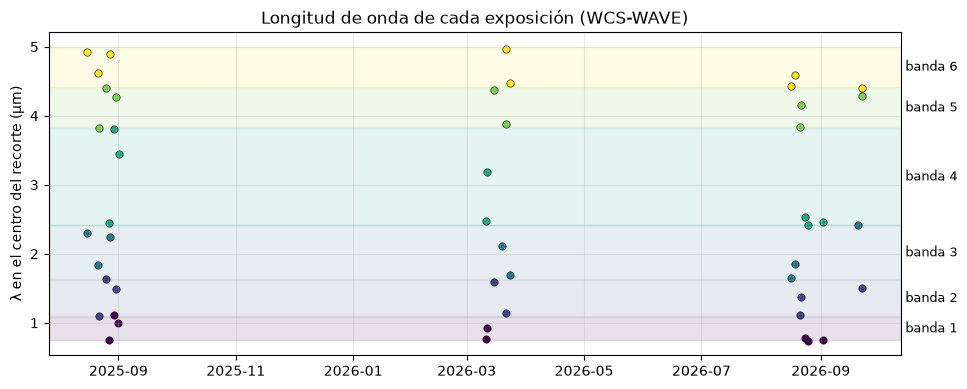

In [16]:
fig, ax = plt.subplots(figsize=(11, 4.2))
for b, (lo, hi) in spherex.BANDAS_UM.items():
    ax.axhspan(lo, hi, color=COLOR[b], alpha=.12)
    ax.text(1.005, (lo + hi) / 2, f"banda {b}", transform=ax.get_yaxis_transform(), va="center", fontsize=9)
for b, f in muestra:
    if f.lambda_um:
        ax.scatter(pd.Timestamp(Time(f.obs.mjd, format="mjd").datetime), f.lambda_um, color=COLOR[b], s=28, edgecolor="k", lw=.4)
ax.set_ylabel("λ en el centro del recorte (µm)"); ax.grid(alpha=.3)
ax.set_title("Longitud de onda de cada exposición (WCS-WAVE)"); plt.show()

### La λ cambia también dentro de una sola imagen

La tabla `WCS-WAVE` da la λ en cada punto del detector. En un recorte de 0,1° el cambio es pequeño; en el detector
entero (unos 3,5°) se recorre la banda completa. Esta imagen está en el marco del detector, sin girar.

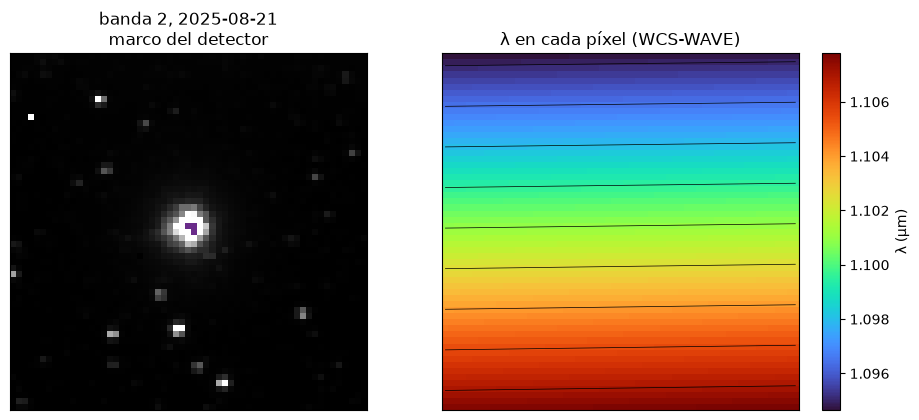

Dentro de este recorte la λ va de 1.0947 a 1.1078 µm (Δ = 13.1 nm); la banda completa va de 1.1 a 1.62 µm.


In [17]:
def mapa_lambda(h):
    """λ (µm) en cada píxel del recorte, interpolando la rejilla de puntos de control de WCS-WAVE."""
    from scipy.ndimage import map_coordinates
    cab, tab = h["IMAGE"].header, h["WCS-WAVE"].data
    xs, ys = np.asarray(tab["X"][0], float), np.asarray(tab["Y"][0], float)
    vals = np.asarray(tab["VALUES"][0], float)
    ny, nx = h["IMAGE"].data.shape
    py_, px_ = np.mgrid[1:ny + 1, 1:nx + 1]                      # 1-based, como FITS
    cx = (px_ - cab["CRPIX1W"]) * cab.get("CDELT1W", 1) + cab.get("CRVAL1W", 1)
    cy = (py_ - cab["CRPIX2W"]) * cab.get("CDELT2W", 1) + cab.get("CRVAL2W", 1)
    fx = np.interp(cx.ravel(), xs, np.arange(len(xs))); fy = np.interp(cy.ravel(), ys, np.arange(len(ys)))
    return map_coordinates(vals[..., 0], [fy, fx], order=1).reshape(ny, nx)

ejemplo = next(f for b, f in muestra if b == BANDA)
with fits.open(spherex.bajar_recorte(ejemplo.obs, RA, DEC, SIZE)) as h:
    lam = mapa_lambda(h); img = h["IMAGE"].data.astype(float) - h["ZODI"].data
fig, axs = plt.subplots(1, 2, figsize=(10, 4.3))
lo, hi = np.nanpercentile(img, [1, 99.5])
axs[0].imshow(img, origin="lower", cmap=GRIS, vmin=lo, vmax=hi); axs[0].set_title(f"banda {BANDA}, {ejemplo.obs.iso[:10]}\nmarco del detector")
im = axs[1].imshow(lam, origin="lower", cmap="turbo"); fig.colorbar(im, ax=axs[1], label="λ (µm)")
axs[1].contour(lam, levels=8, colors="k", linewidths=.5); axs[1].set_title("λ en cada píxel (WCS-WAVE)")
for ax in axs: ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()
lo_b, hi_b = spherex.BANDAS_UM[BANDA]
print(f"Dentro de este recorte la λ va de {lam.min():.4f} a {lam.max():.4f} µm (Δ = {1000*(lam.max()-lam.min()):.1f} nm); "
      f"la banda completa va de {lo_b} a {hi_b} µm.")

## 7.4 El mismo campo en las seis bandas

Una exposición por banda, la más cercana a la mitad del periodo. **Cada panel tiene su propia escala**: el objetivo
es ver qué estrellas destacan en cada longitud de onda, no comparar brillos entre paneles.
Verde = posición predicha del objeto; cian = la estrella de referencia de la sección 7.5.

Estrella de referencia en el píxel (np.int64(31), np.int64(45))


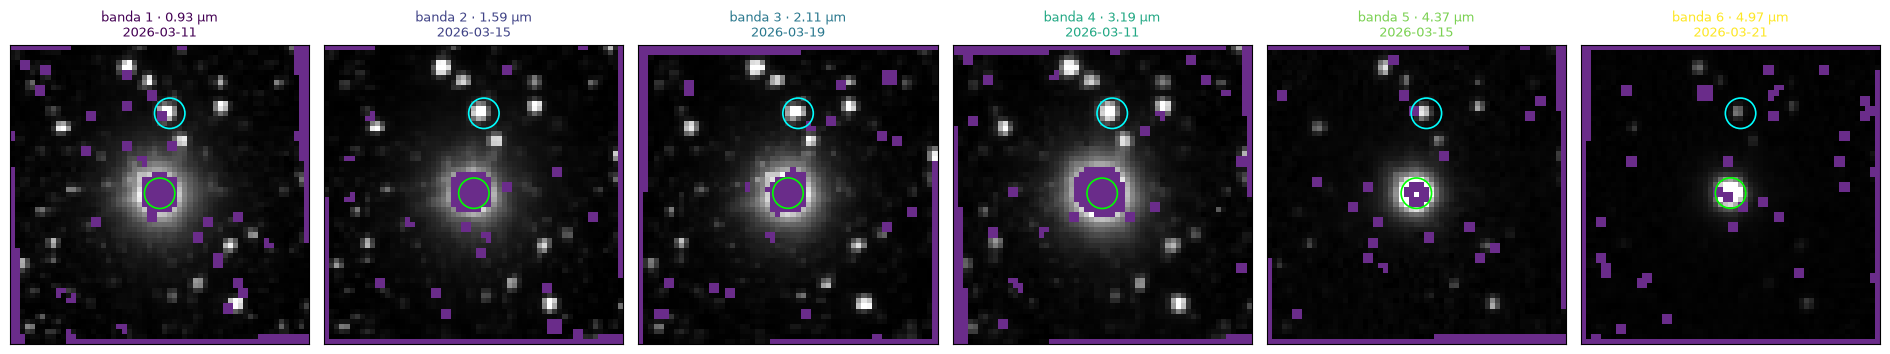

In [18]:
from scipy.ndimage import maximum_filter
PX_SR = (spherex.ESCALA_ARCSEC / 206264.806) ** 2          # ángulo sólido de un píxel

def flujo(d, x0, y0, r=2.5):
    """Fotometría de apertura simple en mJy (indicativa). NaN si falta algún píxel de la apertura."""
    yy, xx = np.mgrid[:N_PX, :N_PX]; r2 = (xx - x0)**2 + (yy - y0)**2
    ap, an = r2 <= r**2, (r2 > (r + 3)**2) & (r2 <= (r + 7)**2)
    if not np.all(np.isfinite(d[ap])): return np.nan
    return float(np.sum(d[ap] - np.nanmedian(d[an])) * PX_SR * 1e9)   # MJy/sr · sr → mJy

# Estrella de referencia: la más brillante, lejos del centro y del borde, medible en la mayoría de exposiciones.
ref = next(f for b, f in muestra if b == BANDA).datos
cand = (ref == maximum_filter(np.nan_to_num(ref, nan=-np.inf), size=5)) & np.isfinite(ref)
yy, xx = np.mgrid[:N_PX, :N_PX]
cand &= (np.hypot(xx - N_PX / 2, yy - N_PX / 2) > 8) & (xx > 8) & (xx < N_PX - 9) & (yy > 8) & (yy < N_PX - 9)
ESTRELLA = None
for k in np.argsort(-np.where(cand, ref, -np.inf), axis=None)[:15]:
    y0, x0 = np.unravel_index(k, ref.shape)
    if np.mean([np.isfinite(flujo(f.datos, x0, y0)) for _, f in muestra]) >= 0.8:
        ESTRELLA = (x0, y0); break
print("Estrella de referencia en el píxel", ESTRELLA)

medio = np.median([f.obs.mjd for _, f in muestra])
fig, axs = plt.subplots(1, 6, figsize=(19, 3.9))
for ax, b in zip(axs, range(1, 7)):
    fs = [f for bb, f in muestra if bb == b]
    if not fs: ax.set_title(f"banda {b}: sin datos"); ax.axis("off"); continue
    f = min(fs, key=lambda x: abs(x.obs.mjd - medio))
    ax.imshow(norma([f])(f.datos), origin="lower", cmap=GRIS, vmin=0, vmax=1); marcar(ax, f)
    if ESTRELLA: ax.add_patch(plt.Circle(ESTRELLA, 3, fill=False, color="cyan", lw=1.2))
    encuadrar(ax); ax.set_title(f"banda {b} · {f.lambda_um:.2f} µm\n{f.obs.iso[:10]}", fontsize=9, color=COLOR[b])
fig.tight_layout(); plt.show()

## 7.5 Un espectro hecho con todas las exposiciones

Medimos el flujo de la estrella de referencia en cada exposición y lo ponemos contra **λ** (izquierda) y contra la
**fecha** (derecha). Si los puntos se ordenan en una curva suave contra λ y saltan sin orden contra la fecha, los
cambios de brillo que se ven en el parpadeo son del filtro, no de la estrella.

Se intenta lo mismo con el objeto del campo: si está saturado (como Barnard), no se puede medir y se avisa.

Estrella de Barnard: solo 0 exposiciones medibles (núcleo saturado o fuera del campo); no se grafica.


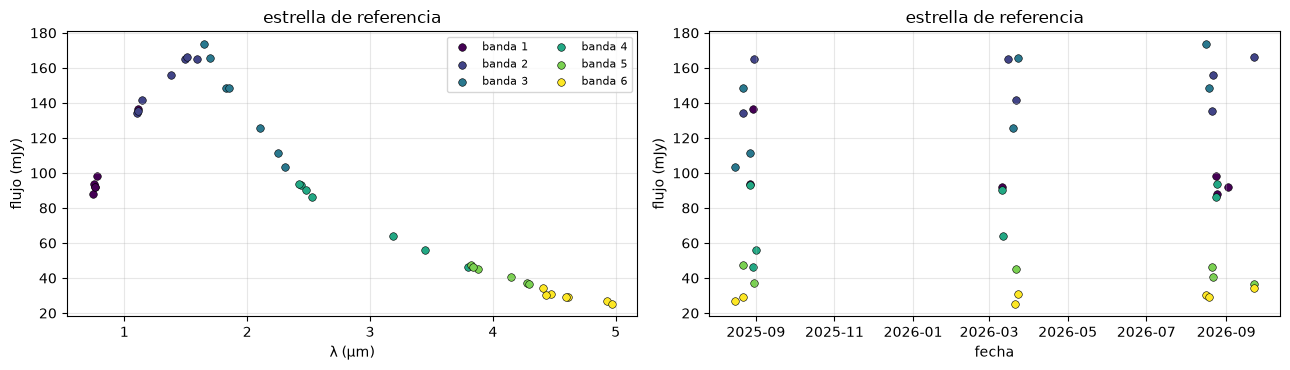

In [19]:
def espectro(x0, y0, x_y_por_exposicion=None):
    filas = []
    for b, f in muestra:
        x, y = x_y_por_exposicion(f) if x_y_por_exposicion else (x0, y0)
        filas.append(dict(banda=b, lam=f.lambda_um, fecha=pd.Timestamp(Time(f.obs.mjd, format="mjd").datetime),
                          mJy=flujo(f.datos, x, y)))
    return pd.DataFrame(filas).dropna()

series = {}
if ESTRELLA: series["estrella de referencia"] = espectro(*ESTRELLA)
obj = espectro(0, 0, lambda f: W.world_to_pixel_values(*posicion(anio(f))))
if len(obj) >= 3: series[c["nombre"]] = obj
else: print(f"{c['nombre']}: solo {len(obj)} exposiciones medibles (núcleo saturado o fuera del campo); no se grafica.")

fig, axs = plt.subplots(len(series), 2, figsize=(13, 3.8 * len(series)), squeeze=False)
for fila, (nombre, s) in zip(axs, series.items()):
    for b, g_ in s.groupby("banda"):
        fila[0].scatter(g_["lam"], g_["mJy"], color=COLOR[b], s=30, edgecolor="k", lw=.4, label=f"banda {b}")
        fila[1].scatter(g_["fecha"], g_["mJy"], color=COLOR[b], s=30, edgecolor="k", lw=.4)
    fila[0].set_xlabel("λ (µm)"); fila[1].set_xlabel("fecha")
    for ax in fila: ax.set_ylabel("flujo (mJy)"); ax.grid(alpha=.3); ax.set_title(nombre)
    fila[0].legend(fontsize=8, ncol=2)
plt.tight_layout(); plt.show()

**Qué mirar:** contra λ, los puntos de cada banda empalman con los de la banda vecina y dibujan la forma del
espectro de la estrella; contra la fecha, el mismo flujo salta de arriba abajo sin patrón. Esto es lo que hace
SPHEREx: un espectro de todo el cielo a partir de imágenes. La fotometría es de apertura simple y sin corrección de
PSF: sirve para ver la forma, no para dar cifras.

---
# 8. Cómo armar el parpadeo del visor: a), b) y c)

La idea del visor: **tomar varios frames de un punto y ver si algo se mueve**, en la banda que elija el usuario.
Esta sección muestra con datos reales las tres cosas que hay que cuidar:

- **a)** los frames tienen que ser de **visitas distintas**: dentro de una visita nada se mueve;
- **b)** de cada visita, elegir la exposición donde el objeto quedó al **mismo color (λ igualada)**, para que no "lata";
- **c)** el movimiento es de **1–2 px**: hace falta zoom y una marca fija para verlo.

## Herramienta: la λ del objeto en **todas** las exposiciones, sin bajar imágenes

La tabla píxel → λ (`WCS-WAVE`) es **fija para cada detector** (hallazgo de `eda/espectral.py`). Así que para saber a
qué λ quedó el objeto en una exposición basta con:

1. la tabla del detector, que se saca una vez de cualquier recorte, y
2. la **cabecera** del archivo (los primeros 70 KB, pedidos con HTTP `Range`), que dice dónde cayó el objeto en el detector.

Son ~0,3 s y 70 KB por exposición, en vez de ~8 s y 4 MB de un recorte. Comprobado contra el recorte: misma λ con 0,0001 µm de diferencia.

In [20]:
import hashlib, time
from concurrent.futures import ThreadPoolExecutor
from scipy.ndimage import map_coordinates

DIR_CAB = spherex.CACHE / "cabeceras"; DIR_CAB.mkdir(parents=True, exist_ok=True)

def cabecera(o):
    """Cabecera de la extensión IMAGE del archivo completo, con una petición parcial (cacheada en disco)."""
    ruta = DIR_CAB / (hashlib.sha1(o.access_url.encode()).hexdigest() + ".hdr")
    if not ruta.exists():
        for intento in range(4):
            r = spherex._cliente.get(o.access_url, headers={"Range": "bytes=0-69119"})
            if r.status_code in (200, 206): break
            time.sleep(2 * 2**intento)
        r.raise_for_status()
        txt = r.content.decode("ascii", "replace")
        fin = txt.index("END" + " " * 77) + 80                # fin de la cabecera primaria
        ruta.write_text(txt[((fin + 2879) // 2880) * 2880:])  # la de IMAGE empieza en el bloque siguiente
    return fits.Header.fromstring(ruta.read_text(), sep="")

def tabla_lambda(banda, o_muestra):
    """Rejilla WCS-WAVE del detector, sacada de un recorte cualquiera de esa banda."""
    with fits.open(spherex.bajar_recorte(o_muestra, RA, DEC, SIZE)) as h:
        t = h["WCS-WAVE"].data
        return np.asarray(t["X"][0], float), np.asarray(t["Y"][0], float), np.asarray(t["VALUES"][0], float)

def lambda_del_objeto(o, tabla):
    xs, ys, vals = tabla
    h = cabecera(o)
    x, y = WCS(h).all_world2pix(*posicion(Time(o.mjd, format="mjd").decimalyear), 0)   # 0-based
    X = (x + 1 - h.get("CRPIX1W", 1)) * h.get("CDELT1W", 1) + h.get("CRVAL1W", 1)       # 1-based, convención W
    Y = (y + 1 - h.get("CRPIX2W", 1)) * h.get("CDELT2W", 1) + h.get("CRVAL2W", 1)
    fx, fy = np.interp(X, xs, np.arange(len(xs))), np.interp(Y, ys, np.arange(len(ys)))
    return float(map_coordinates(vals[..., 0], [[fy], [fx]], order=1)[0]), float(x), float(y)

def inventario_lambda(banda):
    """Todas las exposiciones de la banda con su visita y la λ a la que quedó el objeto."""
    vis = visitas_de(banda)
    tabla = tabla_lambda(banda, vis[0][0])
    todas = [(i, o) for i, v in enumerate(vis) for o in v]
    with ThreadPoolExecutor(spherex.PARALELO) as ex:
        res = list(ex.map(lambda par: lambda_del_objeto(par[1], tabla), todas))
    df = pd.DataFrame([dict(visita=i, obs=o, mjd=o.mjd, fecha=pd.Timestamp(Time(o.mjd, format="mjd").datetime),
                            lam=l, x_det=x, y_det=y) for (i, o), (l, x, y) in zip(todas, res)])
    return vis, df

t0 = time.time()
vis_b, inv_b = inventario_lambda(BANDA)
print(f"Banda {BANDA}: λ de {len(inv_b)} exposiciones en {time.time() - t0:.1f} s")
inv_b.groupby("visita").agg(desde=("fecha", "min"), hasta=("fecha", "max"), exposiciones=("lam", "size"),
                            lam_min=("lam", "min"), lam_max=("lam", "max")).round(3)

Banda 2: λ de 62 exposiciones en 8.7 s


,desde,hasta,exposiciones,lam_min,lam_max
visita,,,,,
0,2025-08-21 23:33:58.665600,2025-08-30 16:10:28.416000,18,1.101,1.629
1,2026-03-15 00:46:05.059200,2026-03-22 05:28:36.912000,19,1.094,1.629
2,2026-08-18 20:48:38.822400,2026-08-28 03:59:24.950400,24,1.088,1.661
3,2026-09-22 15:04:21.014400,2026-09-22 15:04:21.014400,1,1.512,1.512


## a) Los frames tienen que ser de visitas distintas

Cada punto es una exposición; la posición es la que **predice el movimiento propio** para su fecha, en píxeles
respecto de la primera. Dentro de una visita (mismo color) los puntos casi se superponen; entre visitas se separan.

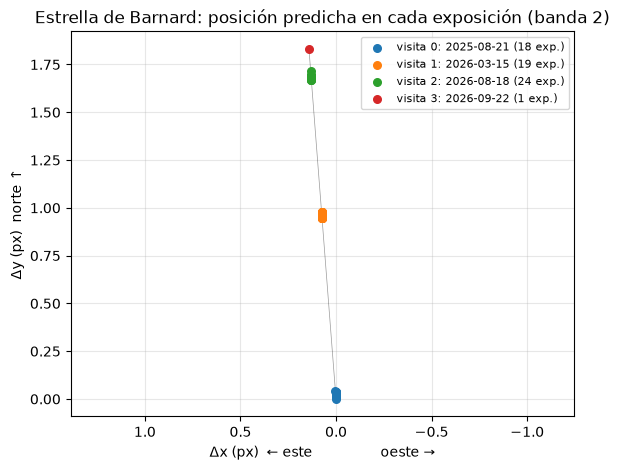

,visita,dias_dentro,px_dentro,px_desde_visita_anterior
0,0,8.7,0.04,NaN
1,1,7.2,0.03,0.94
2,2,9.3,0.04,0.73
3,3,0.0,0.00,0.15


In [21]:
p0 = W.world_to_pixel_values(*posicion(Time(inv_b.mjd.min(), format="mjd").decimalyear))
pos = np.array([W.world_to_pixel_values(*posicion(Time(m, format="mjd").decimalyear)) for m in inv_b.mjd]) - p0
fig, ax = plt.subplots(figsize=(6.5, 5))
for i, g_ in inv_b.groupby("visita"):
    sel = pos[g_.index]
    ax.scatter(sel[:, 0], sel[:, 1], s=30, label=f"visita {i}: {g_.fecha.min():%Y-%m-%d} ({len(g_)} exp.)", zorder=3)
ax.plot(pos[:, 0], pos[:, 1], color="k", lw=.5, alpha=.4)
ax.set_xlabel("Δx (px)  ← este                 oeste →"); ax.set_ylabel("Δy (px)  norte ↑")
ax.invert_xaxis(); ax.set_aspect("equal", "datalim"); ax.grid(alpha=.3); ax.legend(fontsize=8)
ax.set_title(f"{c['nombre']}: posición predicha en cada exposición (banda {BANDA})"); plt.show()

filas = []
for i, g_ in inv_b.groupby("visita"):
    pv = pos[g_.index]
    filas.append(dict(visita=i, dias_dentro=round(g_.mjd.max() - g_.mjd.min(), 1),
                      px_dentro=round(float(np.hypot(*(pv.max(0) - pv.min(0)))), 2)))
res = pd.DataFrame(filas)
centros = np.array([pos[g_.index].mean(0) for _, g_ in inv_b.groupby("visita")])
res["px_desde_visita_anterior"] = [np.nan] + [round(float(np.hypot(*(centros[k] - centros[k - 1]))), 2) for k in range(1, len(centros))]
res

Lo mismo, visto como parpadeo. **Izquierda:** varias exposiciones sueltas de **una misma visita** (no hay movimiento,
pero el brillo cambia porque cada una está a otro color). **Derecha:** un frame por visita (el movimiento se acumula).

In [22]:
def parpadeo_lado_a_lado(paneles, ms=800, zoom=None, cruz=None):
    """paneles = [(titulo, [Fotograma...]), ...]. Misma escala para todos los paneles.
    cruz = (x, y) fija en píxeles: una marca que no se mueve para comparar posiciones."""
    n = norma([f for _, fs in paneles for f in fs])
    fig, axs = plt.subplots(1, len(paneles), figsize=(5 * len(paneles), 5.4), squeeze=False)
    arts = []
    for ax, (titulo, fs) in zip(axs[0], paneles):
        im = ax.imshow(n(fs[0].datos), origin="lower", cmap=GRIS, vmin=0, vmax=1, interpolation="nearest")
        circ = plt.Circle((0, 0), 3, fill=False, color="lime", lw=1.2); ax.add_patch(circ)
        if cruz is not None:
            ax.axvline(cruz[0], color="orange", lw=.8, ls="--"); ax.axhline(cruz[1], color="orange", lw=.8, ls="--")
        ax.set_xticks([]); ax.set_yticks([])
        if zoom:
            cx, cy = cruz if cruz is not None else (N_PX / 2, N_PX / 2)
            ax.set_xlim(cx - zoom, cx + zoom); ax.set_ylim(cy - zoom, cy + zoom)
        arts.append((ax, im, circ, titulo, fs))
    def paso(i):
        out = []
        for ax, im, circ, titulo, fs in arts:
            f = fs[i % len(fs)]
            im.set_data(n(f.datos)); circ.center = W.world_to_pixel_values(*posicion(anio(f)))
            lam = f"{f.lambda_um:.3f} µm" if f.lambda_um else ""
            ax.set_title(f"{titulo}\n{i % len(fs) + 1}/{len(fs)} · {f.obs.iso[:16].replace('T', ' ')} · {lam}", fontsize=9)
            out += [im, circ]
        return out
    an = animation.FuncAnimation(fig, paso, frames=max(len(fs) for *_, fs in arts), interval=ms)
    plt.close(fig)
    return HTML(an.to_jshtml(default_mode="loop"))

def bajar_y_procesar(obs_list):
    def uno(o):
        try:
            f = spherex.procesar(spherex.bajar_recorte(o, RA, DEC, SIZE), o, RA, DEC, N_PX)
        except Exception as e:
            print(f"AVISO: se salta {o.obs_id} ({type(e).__name__})"); return None
        f.datos = f.datos - np.nanmedian(f.datos); return f
    with ThreadPoolExecutor(spherex.PARALELO) as ex:
        return [f for f in ex.map(uno, obs_list) if f is not None]

t = len(vis_b) // 2 if T is None else T
v_t = vis_b[t]
dentro = bajar_y_procesar([v_t[k] for k in np.unique(np.linspace(0, len(v_t) - 1, 6).astype(int))])
parpadeo_lado_a_lado([(f"a) DENTRO de la visita {t} (exposiciones sueltas)", dentro),
                      ("a) ENTRE visitas (un frame por visita)", fot)])

## b) λ igualada: que el objeto quede al mismo color en todos los frames

Cada punto gris es una exposición. **Naranja:** lo que se elegía hasta ahora (las exposiciones del medio de cada
visita). **Verde:** la elección con λ igualada: se busca una λ objetivo y, de cada visita, se toman las `POR_VISITA`
exposiciones más cercanas a ella (luego se combinan con la mediana).

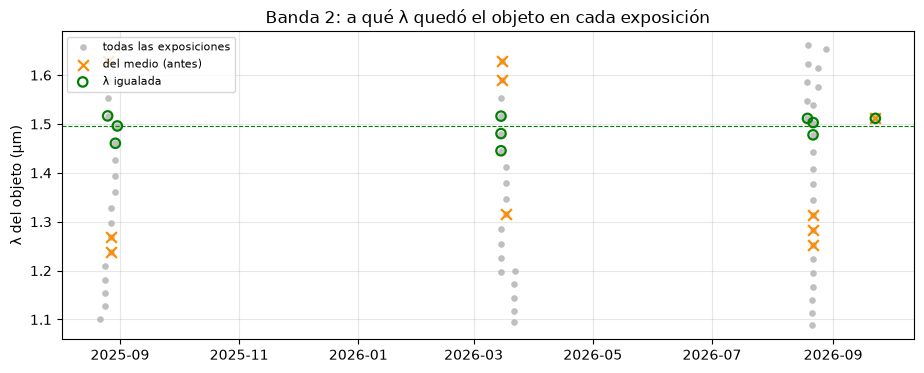

Dispersión de λ entre los frames: del medio = 0.391 µm  →  λ igualada = 0.071 µm (objetivo 1.496 µm). Un canal de esta banda mide ~0.033 µm.


In [23]:
def elegir_medio(vis, k=POR_VISITA):
    return spherex.elegir_fotogramas(vis, max_visitas=len(vis), por_visita=k)

def elegir_lambda_igualada(vis, inv, k=POR_VISITA):
    """Prueba como objetivo la λ de cada exposición y se queda con la que deja la menor dispersión de λ
    entre todas las elegidas (k por visita). Misma idea que eda/03_recortes_y_figuras.py."""
    mejor = (np.inf, None, None)
    for objetivo in inv.lam.dropna().unique():
        grupos = []
        for i in range(len(vis)):
            g_ = inv[inv.visita == i].dropna(subset=["lam"])
            grupos.append(list(g_.iloc[np.argsort(np.abs(g_.lam.values - objetivo))[:k]].obs))
        lams = inv.set_index(inv.obs.map(id)).lam.loc[[id(o) for gr in grupos for o in gr]]
        disp = lams.max() - lams.min()
        if disp < mejor[0]:
            mejor = (disp, objetivo, [sorted(gr, key=lambda o: o.mjd) for gr in grupos])
    return mejor   # (dispersión, λ objetivo, grupos)

def lam_de(inv, grupos):
    m = dict(zip(inv.obs.map(id), inv.lam))
    return [[m[id(o)] for o in gr] for gr in grupos]

def comparar_seleccion(banda, vis, inv):
    g_medio = elegir_medio(vis)
    disp_ig, objetivo, g_ig = elegir_lambda_igualada(vis, inv)
    lm, li = lam_de(inv, g_medio), lam_de(inv, g_ig)
    fig, ax = plt.subplots(figsize=(11, 4))
    ax.scatter(inv.fecha, inv.lam, color="0.75", s=14, label="todas las exposiciones")
    for grupos, lams, col, mk, et in [(g_medio, lm, "darkorange", "x", "del medio (antes)"), (g_ig, li, "green", "o", "λ igualada")]:
        xs_ = [pd.Timestamp(Time(o.mjd, format="mjd").datetime) for gr in grupos for o in gr]
        ax.scatter(xs_, sum(lams, []), color=col, marker=mk, s=60 if mk == "x" else 46,
                   facecolor="none" if mk == "o" else None, lw=1.6, label=et, zorder=3)
    ax.axhline(objetivo, color="green", lw=.8, ls="--")
    ax.set_ylabel("λ del objeto (µm)"); ax.grid(alpha=.3); ax.legend(fontsize=8)
    ax.set_title(f"Banda {banda}: a qué λ quedó el objeto en cada exposición"); plt.show()
    d_m = max(sum(lm, [])) - min(sum(lm, []))
    print(f"Dispersión de λ entre los frames: del medio = {d_m:.3f} µm  →  λ igualada = {disp_ig:.3f} µm "
          f"(objetivo {objetivo:.3f} µm). Un canal de esta banda mide ~{np.mean(spherex.BANDAS_UM[banda]) / R[banda]:.3f} µm.")
    return g_medio, g_ig

g_medio_b, g_ig_b = comparar_seleccion(BANDA, vis_b, inv_b)

Ahora bajamos los frames con λ igualada y los ponemos junto a los de antes, **con la misma escala**. Para medir
cuánto "late" el brillo, se mide el flujo de varias estrellas quietas del campo en cada frame: con λ igualada
deberían brillar casi igual en todos.

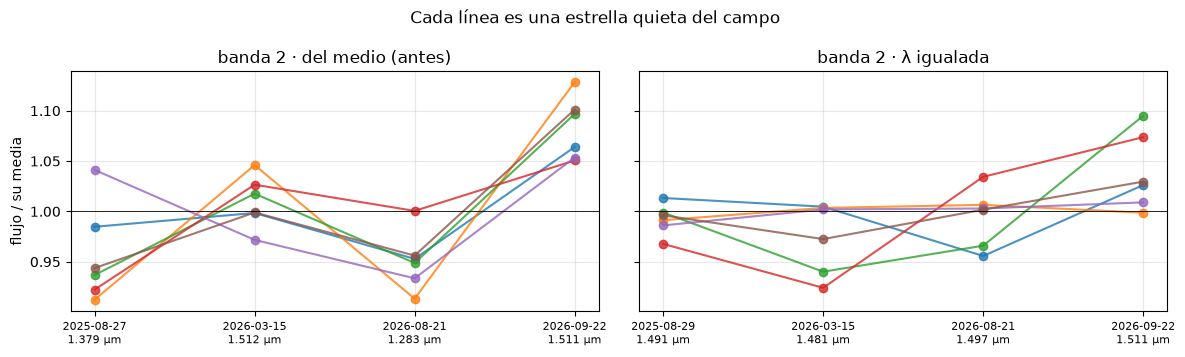

'Latido' mediano de las estrellas quietas: del medio = 5.6 %  →  λ igualada = 2.3 %


In [24]:
def cargar_grupos(grupos):
    fs = []
    for gr in grupos:
        partes = bajar_y_procesar(gr)
        if partes:
            f = spherex.apilar(partes); f.datos = f.datos - np.nanmedian(f.datos); fs.append(f)
    return fs

def estrellas_quietas(fs, n_max=6):
    """Estrellas brillantes, lejos del objeto, con apertura completa en todos los frames."""
    ref = np.nanmedian(np.stack([f.datos for f in fs]), axis=0)
    cand = (ref == maximum_filter(np.nan_to_num(ref, nan=-np.inf), size=5)) & np.isfinite(ref)
    yy, xx = np.mgrid[:N_PX, :N_PX]
    cand &= (np.hypot(xx - N_PX / 2, yy - N_PX / 2) > 8) & (xx > 8) & (xx < N_PX - 9) & (yy > 8) & (yy < N_PX - 9)
    out = []
    for k in np.argsort(-np.where(cand, ref, -np.inf), axis=None)[:40]:
        y0, x0 = np.unravel_index(k, ref.shape)
        if all(np.isfinite(flujo(f.datos, x0, y0)) for f in fs):
            out.append((x0, y0))
        if len(out) == n_max: break
    return out

def latido(fs, estrellas):
    """Dispersión del flujo de cada estrella entre frames, en % de su media."""
    m = np.array([[flujo(f.datos, x, y) for f in fs] for x, y in estrellas])
    return m, 100 * np.std(m, axis=1) / np.mean(m, axis=1)

def comparar_latido(banda, fs_medio, fs_ig):
    est = estrellas_quietas(fs_medio + fs_ig)
    if not est:
        print("No hay estrellas quietas medibles en todos los frames."); return
    m_m, d_m = latido(fs_medio, est); m_i, d_i = latido(fs_ig, est)
    fig, axs = plt.subplots(1, 2, figsize=(12, 3.6), sharey=True)
    for ax, mm, fs, tit in [(axs[0], m_m, fs_medio, "del medio (antes)"), (axs[1], m_i, fs_ig, "λ igualada")]:
        for fila in mm: ax.plot(range(len(fs)), fila / fila.mean(), "o-", alpha=.8)
        ax.set_xticks(range(len(fs)), [f"{f.obs.iso[:10]}\n{f.lambda_um:.3f} µm" for f in fs], fontsize=8)
        ax.axhline(1, color="k", lw=.6); ax.grid(alpha=.3); ax.set_title(f"banda {banda} · {tit}")
    axs[0].set_ylabel("flujo / su media"); fig.suptitle("Cada línea es una estrella quieta del campo"); plt.tight_layout(); plt.show()
    print(f"'Latido' mediano de las estrellas quietas: del medio = {np.median(d_m):.1f} %  →  λ igualada = {np.median(d_i):.1f} %")

fot_ig = cargar_grupos(g_ig_b)
comparar_latido(BANDA, fot, fot_ig)
parpadeo_lado_a_lado([("b) del medio de cada visita (antes)", fot), ("b) λ igualada", fot_ig)])

## c) El movimiento es chico: zoom + una marca fija

Zoom de ±`ZOOM_C` píxeles alrededor del objeto, **sin suavizar** (cada cuadradito es un píxel de 6,15″). La cruz naranja
queda **fija** en la posición de la primera visita: si el objeto se mueve, se ve cómo se separa de ella. El círculo verde
sigue la posición predicha.

Debajo, el desplazamiento **medido** (centroide en una ventana de 5×5 px) contra el **predicho**. Si el núcleo viene
enmascarado (estrella saturada, como Barnard) el centroide no se puede medir y se dice: es el "indicador de saturación"
que pide la tarea 7.

In [25]:
ZOOM_C = 8

def centroide(d, x0, y0, r=2):
    """Centroide ponderado por flujo en una ventana (2r+1)²; None si falta algún píxel (saturado/enmascarado)."""
    xi, yi = int(round(x0)), int(round(y0))
    v = d[yi - r: yi + r + 1, xi - r: xi + r + 1]
    if v.shape != (2 * r + 1, 2 * r + 1) or not np.all(np.isfinite(v)): return None
    v = np.clip(v - np.median(v), 0, None)
    if v.sum() <= 0: return None
    yy, xx = np.mgrid[-r: r + 1, -r: r + 1]
    return xi + (xx * v).sum() / v.sum(), yi + (yy * v).sum() / v.sum()

def tabla_movimiento(fs):
    p_ini = np.array(W.world_to_pixel_values(*posicion(anio(fs[0]))))
    c_ini = None; filas = []
    for f in fs:
        p = np.array(W.world_to_pixel_values(*posicion(anio(f))))
        cen = centroide(f.datos, *p)
        if c_ini is None and cen is not None: c_ini = np.array(cen)
        med = (np.array(cen) - c_ini) if (cen is not None and c_ini is not None) else (np.nan, np.nan)
        filas.append(dict(fecha=f.obs.iso[:10], lam_um=round(f.lambda_um, 3),
                          predicho_dx=round(p[0] - p_ini[0], 2), predicho_dy=round(p[1] - p_ini[1], 2),
                          medido_dx=round(med[0], 2), medido_dy=round(med[1], 2),
                          saturado="sí (núcleo enmascarado)" if cen is None else "no"))
    return pd.DataFrame(filas)

def vista_visor(banda, fs):
    cruz = W.world_to_pixel_values(*posicion(anio(fs[0])))
    display(parpadeo_lado_a_lado([(f"c) {c['nombre']} · banda {banda} · zoom ±{ZOOM_C} px", fs)],
                                 zoom=ZOOM_C, cruz=cruz))
    tm = tabla_movimiento(fs)
    display(tm)
    if (tm.saturado != "no").all():
        print("Objeto saturado en todos los frames: el movimiento se ve, pero no se puede medir con centroide. "
              "En la resta deja un par rojo/azul aunque una estrella saturada no se mueva: el visor debería avisarlo.")

vista_visor(BANDA, fot_ig)

,fecha,lam_um,predicho_dx,predicho_dy,medido_dx,medido_dy,saturado
0,2025-08-29,1.491,0.00,0.00,NaN,NaN,sí (núcleo enmascarado)
1,2026-03-15,1.481,0.07,0.91,NaN,NaN,sí (núcleo enmascarado)
2,2026-08-21,1.497,0.13,1.65,NaN,NaN,sí (núcleo enmascarado)
3,2026-09-22,1.511,0.14,1.80,NaN,NaN,sí (núcleo enmascarado)


Objeto saturado en todos los frames: el movimiento se ve, pero no se puede medir con centroide. En la resta deja un par rojo/azul aunque una estrella saturada no se mueva: el visor debería avisarlo.


### Resta opcional (el "botón" del visor)

No es la vista principal, pero ayuda a verlo a la primera: última − primera, con zoom. Rojo = donde está ahora,
azul = donde estaba.

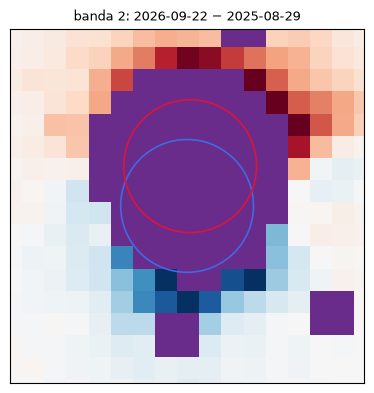

In [26]:
def resta_zoom(banda, fs):
    r = fs[-1].datos - fs[0].datos
    lim = np.nanpercentile(np.abs(r[np.isfinite(r)]), 99.5)
    cruz = W.world_to_pixel_values(*posicion(anio(fs[0])))
    fig, ax = plt.subplots(figsize=(4.6, 4.6))
    ax.imshow(r, origin="lower", cmap=DIF, vmin=-lim, vmax=lim, interpolation="nearest")
    marcar(ax, fs[0], "royalblue"); marcar(ax, fs[-1], "crimson")
    ax.set_xlim(cruz[0] - ZOOM_C, cruz[0] + ZOOM_C); ax.set_ylim(cruz[1] - ZOOM_C, cruz[1] + ZOOM_C)
    ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(f"banda {banda}: {fs[-1].obs.iso[:10]} − {fs[0].obs.iso[:10]}", fontsize=9); plt.show()

resta_zoom(BANDA, fot_ig)

## Selector de banda: lo mismo en `BANDA_EXTRA`

Todo lo anterior es una función de la banda, así que el visor solo tiene que llamar lo mismo con otra banda.

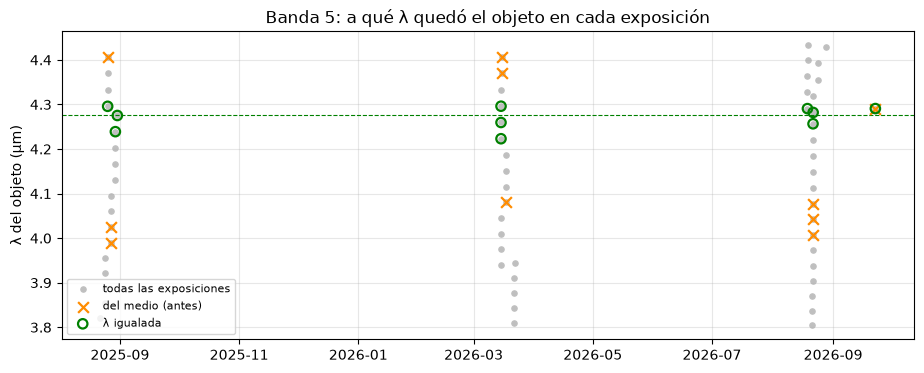

Dispersión de λ entre los frames: del medio = 0.417 µm  →  λ igualada = 0.073 µm (objetivo 4.275 µm). Un canal de esta banda mide ~0.037 µm.


AVISO: se salta 2026W34_2A_0264_1D5 (HTTPStatusError)


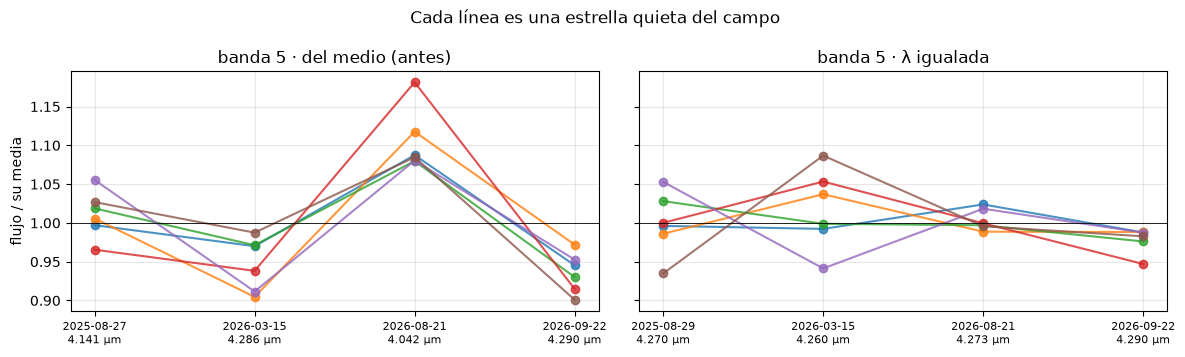

'Latido' mediano de las estrellas quietas: del medio = 6.8 %  →  λ igualada = 2.9 %


,fecha,lam_um,predicho_dx,predicho_dy,medido_dx,medido_dy,saturado
0,2025-08-29,4.270,0.00,0.00,NaN,NaN,sí (núcleo enmascarado)
1,2026-03-15,4.260,0.07,0.91,NaN,NaN,sí (núcleo enmascarado)
2,2026-08-21,4.273,0.13,1.65,NaN,NaN,sí (núcleo enmascarado)
3,2026-09-22,4.290,0.14,1.80,NaN,NaN,sí (núcleo enmascarado)


Objeto saturado en todos los frames: el movimiento se ve, pero no se puede medir con centroide. En la resta deja un par rojo/azul aunque una estrella saturada no se mueva: el visor debería avisarlo.


In [27]:
if BANDA_EXTRA:
    vis_e, inv_e = inventario_lambda(BANDA_EXTRA)
    g_medio_e, g_ig_e = comparar_seleccion(BANDA_EXTRA, vis_e, inv_e)
    fot_ig_e = cargar_grupos(g_ig_e)
    comparar_latido(BANDA_EXTRA, fot_extra, fot_ig_e)
    vista_visor(BANDA_EXTRA, fot_ig_e)

**Resumen para el visor:**

| Paso | Cómo | Costo |
|---|---|---|
| Buscar exposiciones | SIA2, una consulta por banda | ~2 s |
| λ del objeto en cada una | cabecera con HTTP `Range` + tabla `WCS-WAVE` del detector | ~0,3 s y 70 KB por exposición (cacheable) |
| Elegir frames | un grupo por **visita**, con **λ igualada** | nada |
| Bajar y alinear | recorte de cada exposición elegida + reproyección norte-arriba | ~4 MB y 5–12 s por recorte (caché después) |
| Mostrar | parpadeo con **zoom sin suavizar**, cruz fija, λ y fecha en cada frame; resta como botón | — |

---
**Qué NO prueba este notebook:** las imágenes son la mediana de pocas exposiciones y la escala es visual (asinh).
No es fotometría ni astrometría. Para medir el desplazamiento ver `prototipos/rango_fechas/eda_spherex.ipynb`, sección 5.

*This notebook makes use of data products from SPHEREx, a joint project of the Jet Propulsion Laboratory and the
California Institute of Technology, funded by the National Aeronautics and Space Administration.*